# MySQL EDA — `fleet_registry`

Exploratory data analysis on the nine MySQL tables that back the Fleet dbt Lakehouse.

**Use cases covered:** driver performance · route profitability · fleet utilization · fuel efficiency · customer analysis · seasonal patterns

> Companion notebook: `mongo_eda.ipynb` (MongoDB `fleet_operations` collections).


## 1. Setup


In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep", font_scale=1.05)

DATA = Path("..") / "data" / "mysql"
if not DATA.exists():
    DATA = Path("data/mysql")
FIGSIZE = (12, 5)
RANDOM = 42
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("pandas", pd.__version__, "| seaborn", sns.__version__)
print("data dir:", DATA.resolve())


pandas 3.1.1 | seaborn 0.13.2
data dir: C:\Git-Repo\fleet\data\mysql


## 2. Load tables

Parse date columns up front so temporal EDA works without re-casting.


In [2]:
DATE_COLS = {
    "loads": ["load_date"],
    "trips": ["dispatch_date"],
    "drivers": ["hire_date", "termination_date", "date_of_birth"],
    "trucks": ["acquisition_date"],
    "trailers": ["acquisition_date"],
    "customers": ["contract_start_date"],
    "fuel_purchases": ["purchase_date"],
}

tables = {}
for name, dates in DATE_COLS.items():
    tables[name] = pd.read_csv(DATA / f"{name}.csv", parse_dates=dates)

tables["routes"] = pd.read_csv(DATA / "routes.csv")
tables["facilities"] = pd.read_csv(DATA / "facilities.csv")

loads = tables["loads"]
trips = tables["trips"]
drivers = tables["drivers"]
trucks = tables["trucks"]
trailers = tables["trailers"]
customers = tables["customers"]
routes = tables["routes"]
facilities = tables["facilities"]
fuel = tables["fuel_purchases"]

overview = pd.DataFrame(
    {"rows": {k: len(v) for k, v in tables.items()}, "cols": {k: v.shape[1] for k, v in tables.items()}}
).sort_values("rows", ascending=False)
display(overview)


,rows,cols
fuel_purchases,196442,12
loads,85410,13
trips,85410,13
customers,200,9
trailers,180,10
drivers,150,13
trucks,120,12
routes,58,10
facilities,50,10


## 3. Data quality audit

Nulls, duplicates on primary keys, and key column dtypes. FKs are **logical only** (no constraints in MySQL).


,table,rows,null_cells,dup_pk,mem_mb
0,loads,85410,0,0,Index 0.00 load_id ...
1,trips,85410,5066,0,Index 0.00 trip_id ...
2,drivers,150,124,0,Index 0.00 driver_id 0...
3,trucks,120,0,0,Index 0.00 truck_id ...
4,trailers,180,0,0,Index 0.00 trailer_id 0.0...
5,customers,200,0,0,Index 0.00 customer_id ...
6,fuel_purchases,196442,7868,0,Index 0.00 fuel_purchase_id 3.9...
7,routes,58,0,0,Index 0.00 route_id ...
8,facilities,50,0,0,Index 0.00 facility_id 0.00 ...


,accessorial_charges,account_status,acquisition_date,acquisition_mileage,actual_distance_miles,actual_duration_hours,annual_revenue_potential,average_mpg,base_rate_per_mile,booking_type,cdl_class,city,contract_start_date,credit_terms_days,current_location,customer_id,customer_name,customer_type,date_of_birth,destination_city,destination_state,dispatch_date,dock_doors,driver_id,employment_status,...,origin_city,origin_state,pieces,price_per_gallon,primary_freight_type,purchase_date,revenue,route_id,state,status,tank_capacity_gallons,termination_date,total_cost,trailer_id,trailer_number,trailer_type,trip_id,trip_status,truck_id,typical_distance_miles,typical_transit_days,unit_number,vin,weight_lbs,years_experience
trips,NaN,NaN,NaN,NaN,0.00,0.00,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,"1,714.00",NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"1,680.00",NaN,NaN,0.00,0.00,"1,672.00",NaN,NaN,NaN,NaN,NaN,NaN
drivers,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,NaN,0.00,0.00,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,124.00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00
fuel_purchases,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,"3,988.00",NaN,...,NaN,NaN,NaN,0.00,NaN,0.00,NaN,NaN,NaN,NaN,NaN,NaN,0.00,NaN,NaN,NaN,0.00,NaN,"3,880.00",NaN,NaN,NaN,NaN,NaN,NaN


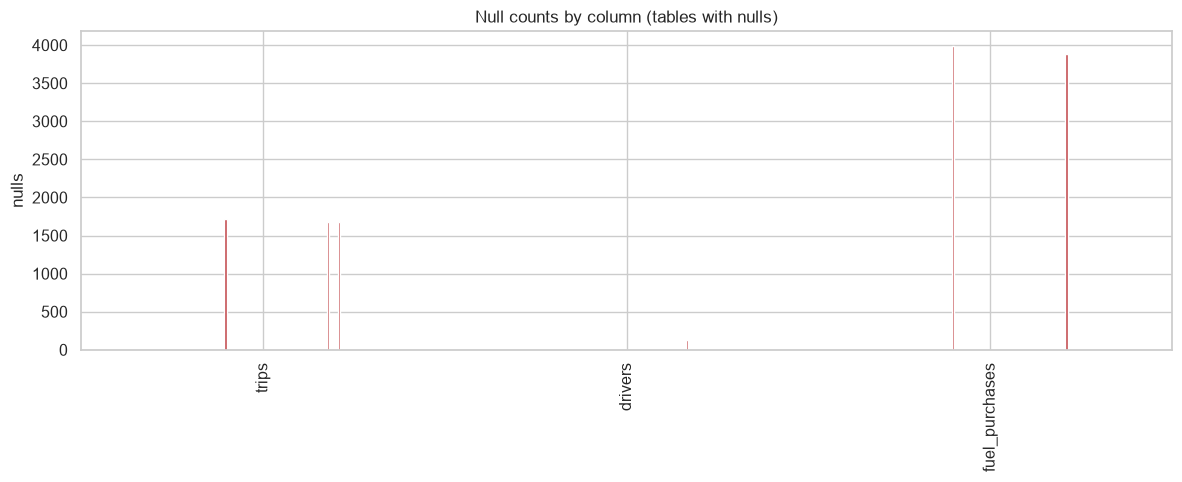

In [3]:
pk = {
    "loads": "load_id", "trips": "trip_id", "drivers": "driver_id", "trucks": "truck_id",
    "trailers": "trailer_id", "customers": "customer_id", "routes": "route_id",
    "facilities": "facility_id", "fuel_purchases": "fuel_purchase_id",
}

rows = []
for name, df in tables.items():
    key = pk[name]
    rows.append({
        "table": name,
        "rows": len(df),
        "null_cells": int(df.isna().sum().sum()),
        "dup_pk": int(df[key].duplicated().sum()),
        "mem_mb": round(df.memory_usage(deep=True) / 1e6, 1),
    })
display(pd.DataFrame(rows))

# Null heatmap (tables with any nulls only)
nulls = {k: v.isna().sum() for k, v in tables.items()}
null_df = pd.DataFrame(nulls)
null_df = null_df.loc[:, null_df.sum() > 0]
if null_df.empty:
    print("No nulls in any table.")
else:
    display(null_df.T)
    ax = null_df.T.plot(kind="bar", figsize=FIGSIZE, legend=False, color="#c44e52")
    ax.set_title("Null counts by column (tables with nulls)")
    ax.set_ylabel("nulls")
    plt.tight_layout()
plt.show()


## 4. Drivers

Employment status, experience, age and CDL class — foundation for the driver-performance mart.


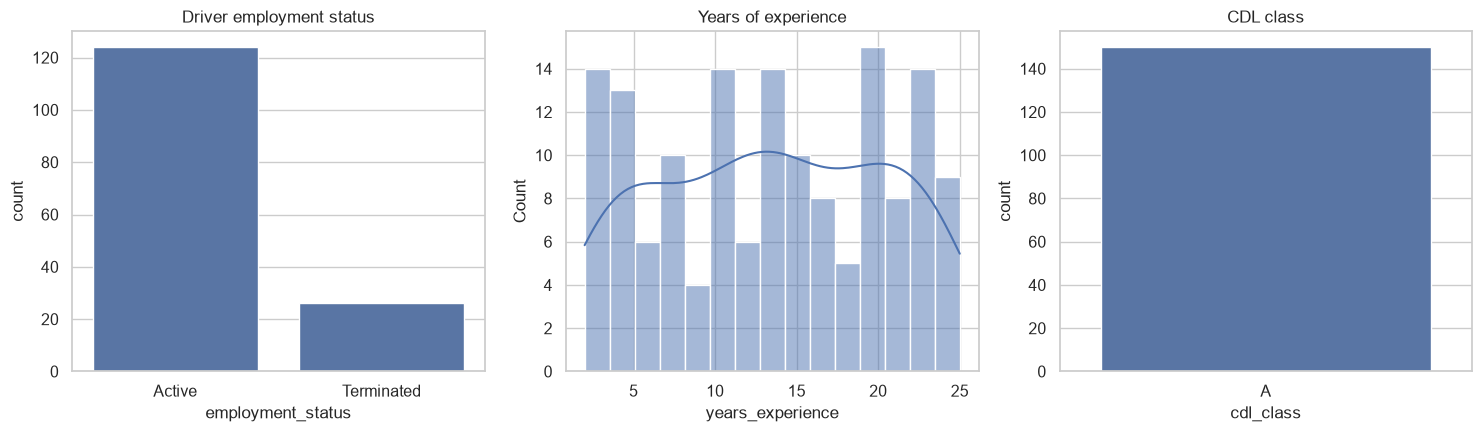

,n,exp_mean,age_mean
employment_status,,,
Active,124,13.70,45.70
Terminated,26,12.50,45.60


Hire years: [2012, 2013, 2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021]
Home terminals: 25 unique


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.countplot(data=drivers, x="employment_status", ax=axes[0], order=["Active", "Terminated"])
axes[0].set_title("Driver employment status")

sns.histplot(data=drivers, x="years_experience", bins=15, kde=True, ax=axes[1], color="#4c72b0")
axes[1].set_title("Years of experience")

sns.countplot(data=drivers, x="cdl_class", ax=axes[2])
axes[2].set_title("CDL class")

plt.tight_layout()
plt.show()

drivers["age"] = (pd.Timestamp("2024-12-31") - drivers["date_of_birth"]).dt.days / 365.25
display(
    drivers.groupby("employment_status")
    .agg(n=("driver_id", "count"), exp_mean=("years_experience", "mean"), age_mean=("age", "mean"))
    .round(1)
)
print("Hire years:", sorted(drivers["hire_date"].dt.year.unique().tolist()))
print("Home terminals:", drivers["home_terminal"].nunique(), "unique")


## 5. Fleet assets — trucks & trailers

Status mix and age profile drive the fleet-utilization and maintenance stories.


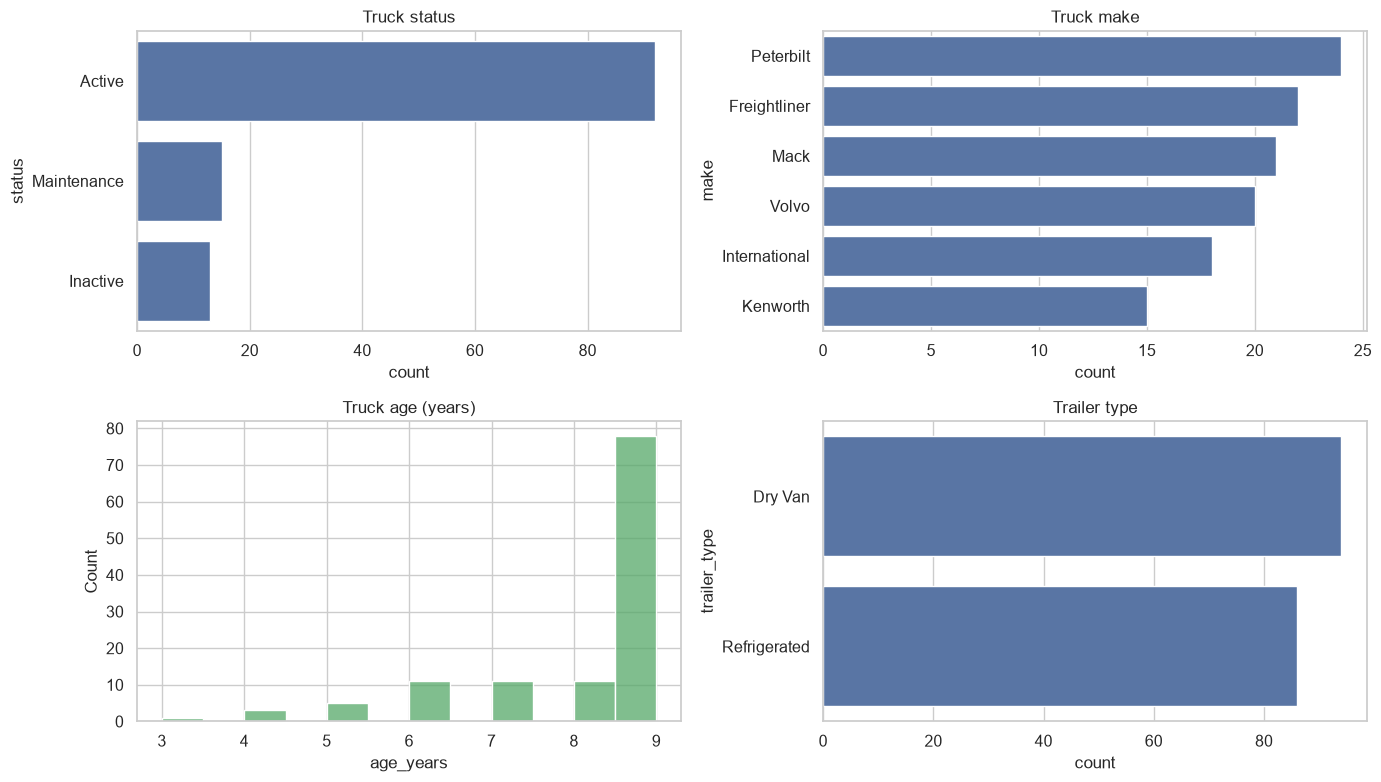

Truck status: {'Active': 92, 'Maintenance': 15, 'Inactive': 13}
Trailer status: {'Active': 180}
Trailer lengths (ft): [53]


In [5]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

sns.countplot(data=trucks, y="status", ax=axes[0, 0], order=trucks["status"].value_counts().index)
axes[0, 0].set_title("Truck status")

sns.countplot(data=trucks, y="make", ax=axes[0, 1], order=trucks["make"].value_counts().index)
axes[0, 1].set_title("Truck make")

trucks["age_years"] = 2024 - trucks["model_year"]
sns.histplot(data=trucks, x="age_years", bins=12, ax=axes[1, 0], color="#55a868")
axes[1, 0].set_title("Truck age (years)")

sns.countplot(data=trailers, y="trailer_type", ax=axes[1, 1], order=trailers["trailer_type"].value_counts().index)
axes[1, 1].set_title("Trailer type")

plt.tight_layout()
plt.show()

print("Truck status:", trucks["status"].value_counts().to_dict())
print("Trailer status:", trailers["status"].value_counts().to_dict())
print("Trailer lengths (ft):", sorted(trailers["length_feet"].unique().tolist()))


## 6. Customers & facilities


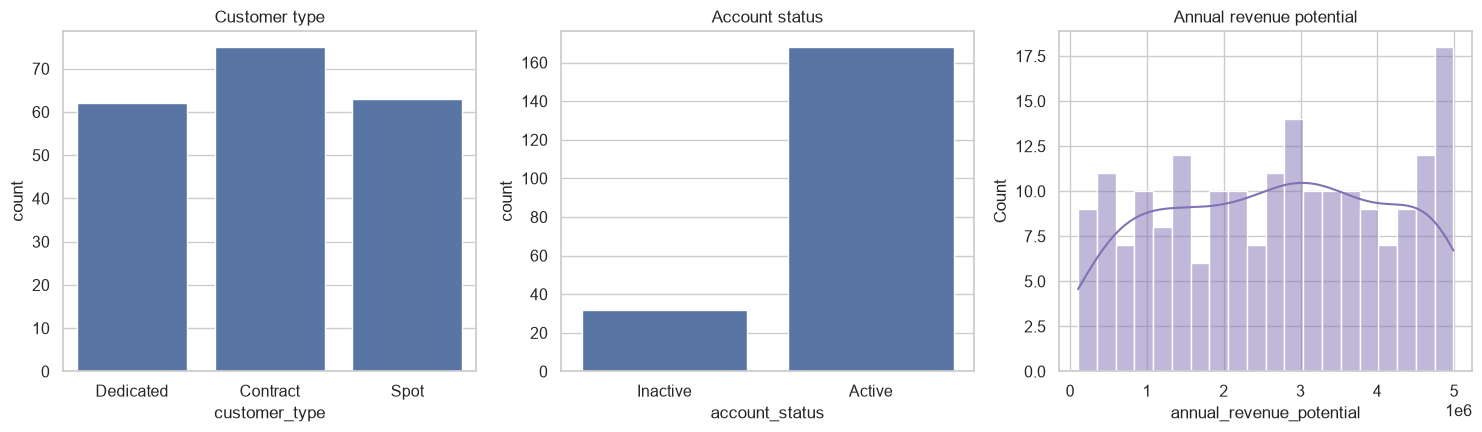

Top freight types: {'Automotive': 41, 'Food/Beverage': 37, 'Retail': 35, 'Electronics': 33, 'Consumer Goods': 30}
Credit terms (days): [15, 30, 45, 60]


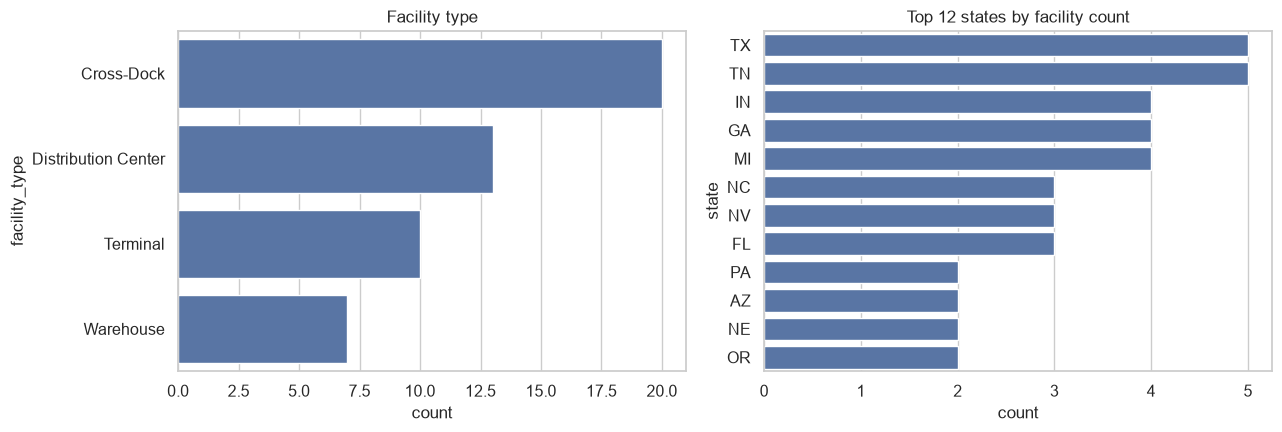

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.countplot(data=customers, x="customer_type", ax=axes[0])
axes[0].set_title("Customer type")

sns.countplot(data=customers, x="account_status", ax=axes[1])
axes[1].set_title("Account status")

sns.histplot(data=customers, x="annual_revenue_potential", bins=20, kde=True, ax=axes[2], color="#8172b2")
axes[2].set_title("Annual revenue potential")

plt.tight_layout()
plt.show()

print("Top freight types:", customers["primary_freight_type"].value_counts().head(5).to_dict())
print("Credit terms (days):", sorted(customers["credit_terms_days"].unique().tolist()))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.countplot(data=facilities, y="facility_type", ax=axes[0], order=facilities["facility_type"].value_counts().index)
axes[0].set_title("Facility type")
sns.countplot(
    data=facilities, y="state", ax=axes[1],
    order=facilities["state"].value_counts().head(12).index,
)
axes[1].set_title("Top 12 states by facility count")
plt.tight_layout()
plt.show()


## 7. Routes (lanes)

Distance, base rate per mile, and transit time — inputs to lane profitability.


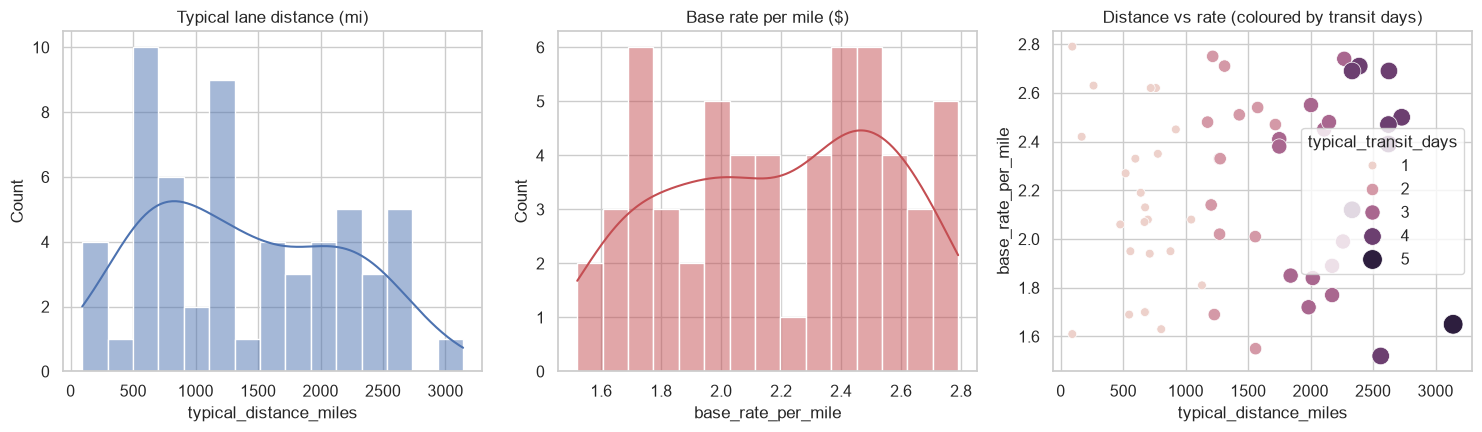

Longest lanes:


,lane,typical_distance_miles,base_rate_per_mile,typical_transit_days
24,FL → WA,3141,1.65,5
15,PA → WA,2729,2.50,4
43,NC → OR,2627,2.69,4
28,WA → NC,2623,2.47,4
41,NC → WA,2623,2.39,4


In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(data=routes, x="typical_distance_miles", bins=15, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Typical lane distance (mi)")

sns.histplot(data=routes, x="base_rate_per_mile", bins=15, kde=True, ax=axes[1], color="#c44e52")
axes[1].set_title("Base rate per mile ($)")

sns.scatterplot(
    data=routes, x="typical_distance_miles", y="base_rate_per_mile",
    hue="typical_transit_days", size="typical_transit_days", ax=axes[2], sizes=(40, 200),
)
axes[2].set_title("Distance vs rate (coloured by transit days)")

plt.tight_layout()
plt.show()

routes["lane"] = routes["origin_state"] + " → " + routes["destination_state"]
print("Longest lanes:")
display(routes.nlargest(5, "typical_distance_miles")[["lane", "typical_distance_miles", "base_rate_per_mile", "typical_transit_days"]])


## 8. Loads — volume, revenue, mix

Three years of completed loads (2022-01-01 → 2024-12-31). Seasonality and booking mix are first-class KPIs.


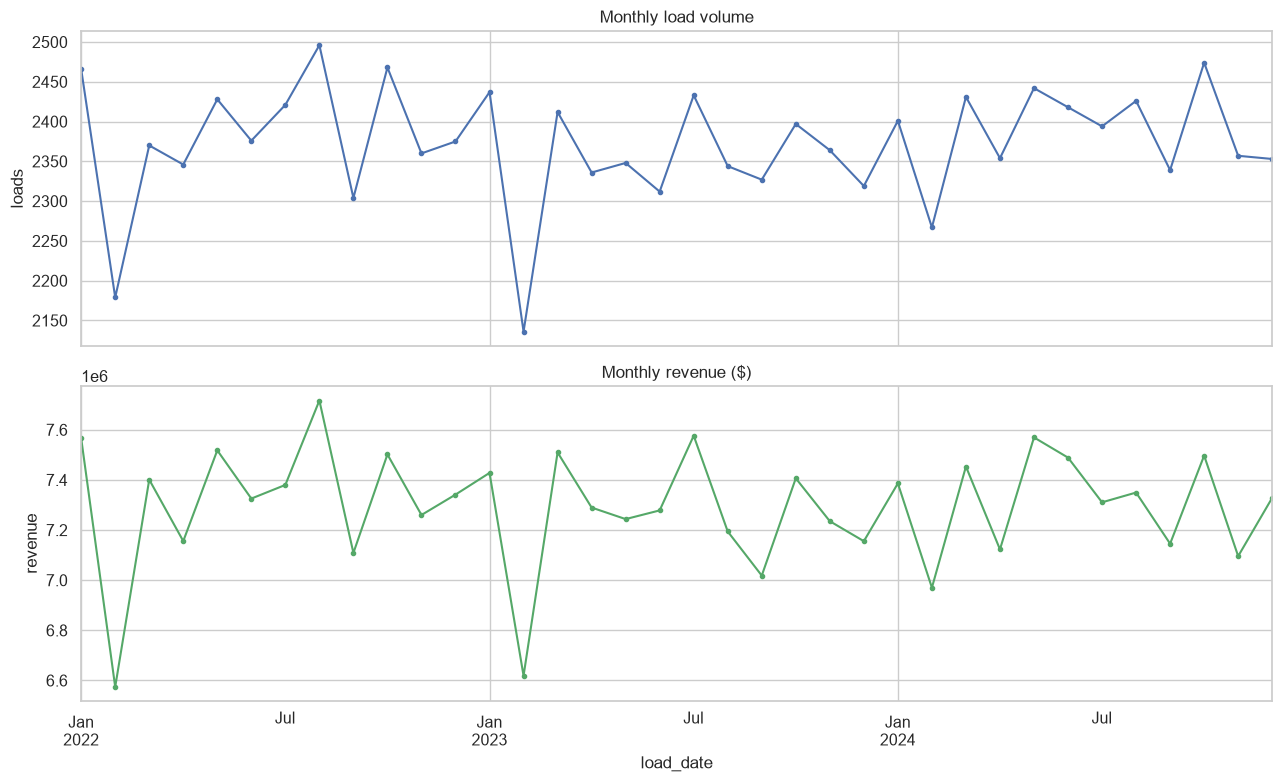

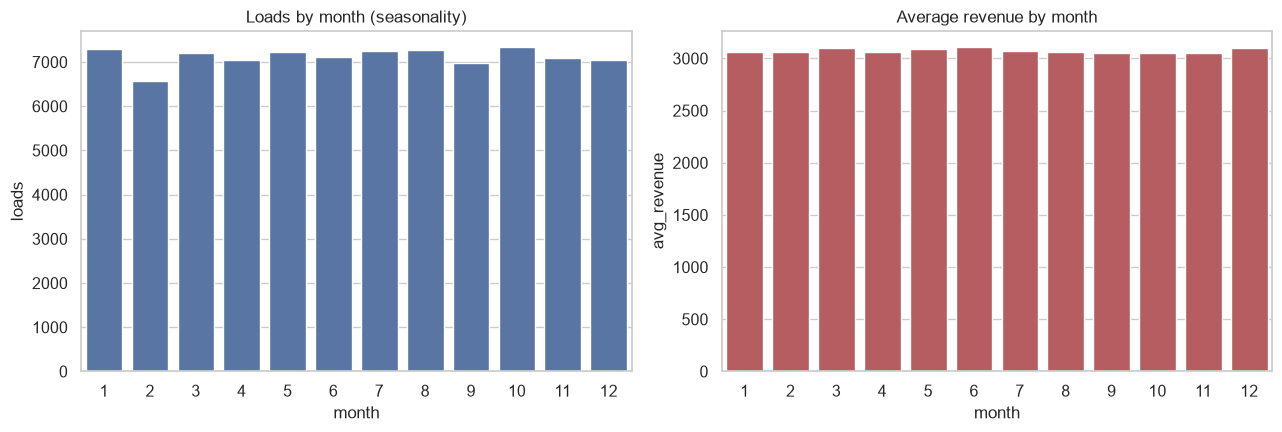

In [8]:
monthly = (
    loads.set_index("load_date")
    .resample("ME")
    .agg(loads=("load_id", "count"), revenue=("revenue", "sum"), weight=("weight_lbs", "mean"))
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
monthly["loads"].plot(ax=axes[0], color="#4c72b0", marker="o", markersize=3)
axes[0].set_title("Monthly load volume")
axes[0].set_ylabel("loads")

monthly["revenue"].plot(ax=axes[1], color="#55a868", marker="o", markersize=3)
axes[1].set_title("Monthly revenue ($)")
axes[1].set_ylabel("revenue")

plt.tight_layout()
plt.show()

loads["month"] = loads["load_date"].dt.month
loads["year"] = loads["load_date"].dt.year
season = loads.groupby("month").agg(loads=("load_id", "count"), avg_revenue=("revenue", "mean"))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=season.index, y=season["loads"], ax=axes[0], color="#4c72b0")
axes[0].set_title("Loads by month (seasonality)")
axes[0].set_xlabel("month")
sns.barplot(x=season.index, y=season["avg_revenue"], ax=axes[1], color="#c44e52")
axes[1].set_title("Average revenue by month")
axes[1].set_xlabel("month")
plt.tight_layout()
plt.show()


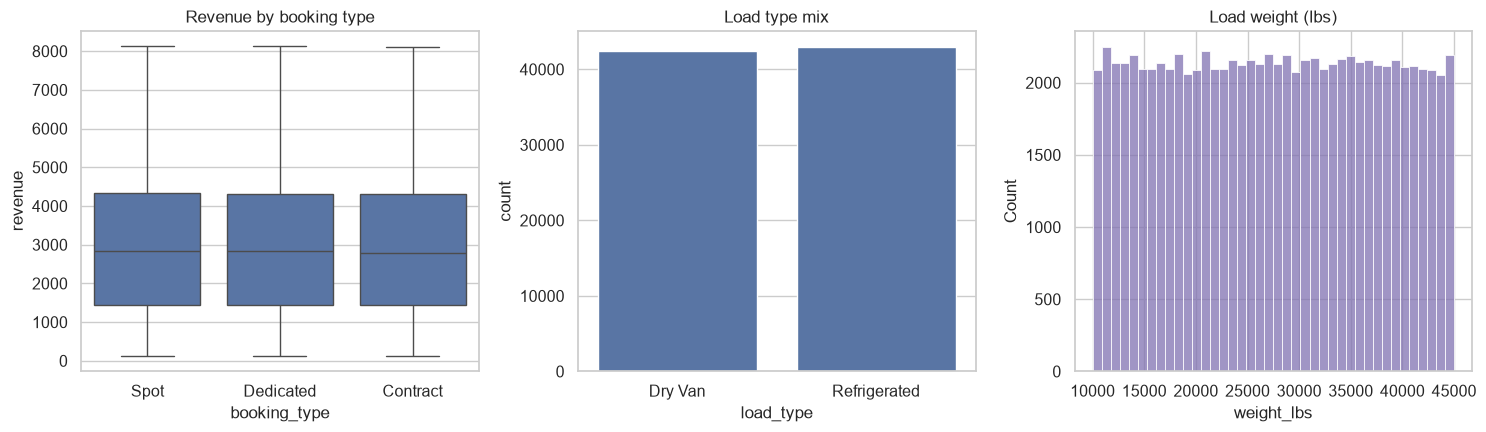

loads  avg_revenue  avg_weight
booking_type load_type                                   
Contract     Dry Van       10659     3,070.20   27,525.50
             Refrigerated  10886     3,053.70   27,399.40
Dedicated    Dry Van       21125     3,078.40   27,512.20
             Refrigerated  21212     3,074.00   27,466.50
Spot         Dry Van       10680     3,071.40   27,439.40
             Refrigerated  10848     3,089.80   27,500.20

Revenue range: 125.93 → 8125.22
Accessorial charges: mean 71.64 | nonzero share 0.623


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.boxplot(data=loads, x="booking_type", y="revenue", ax=axes[0], showfliers=False)
axes[0].set_title("Revenue by booking type")

sns.countplot(data=loads, x="load_type", ax=axes[1])
axes[1].set_title("Load type mix")

sns.histplot(data=loads, x="weight_lbs", bins=40, ax=axes[2], color="#8172b2")
axes[2].set_title("Load weight (lbs)")

plt.tight_layout()
plt.show()

display(
    loads.groupby(["booking_type", "load_type"])
    .agg(loads=("load_id", "count"), avg_revenue=("revenue", "mean"), avg_weight=("weight_lbs", "mean"))
    .round(1)
)
print("Revenue range:", loads["revenue"].min(), "→", loads["revenue"].max())
print("Accessorial charges: mean", round(loads["accessorial_charges"].mean(), 2), "| nonzero share",
      round((loads["accessorial_charges"] > 0).mean(), 3))


## 9. Trips — distance, MPG, idle time

1:1 with loads. MPG and idle are the fuel-efficiency levers.


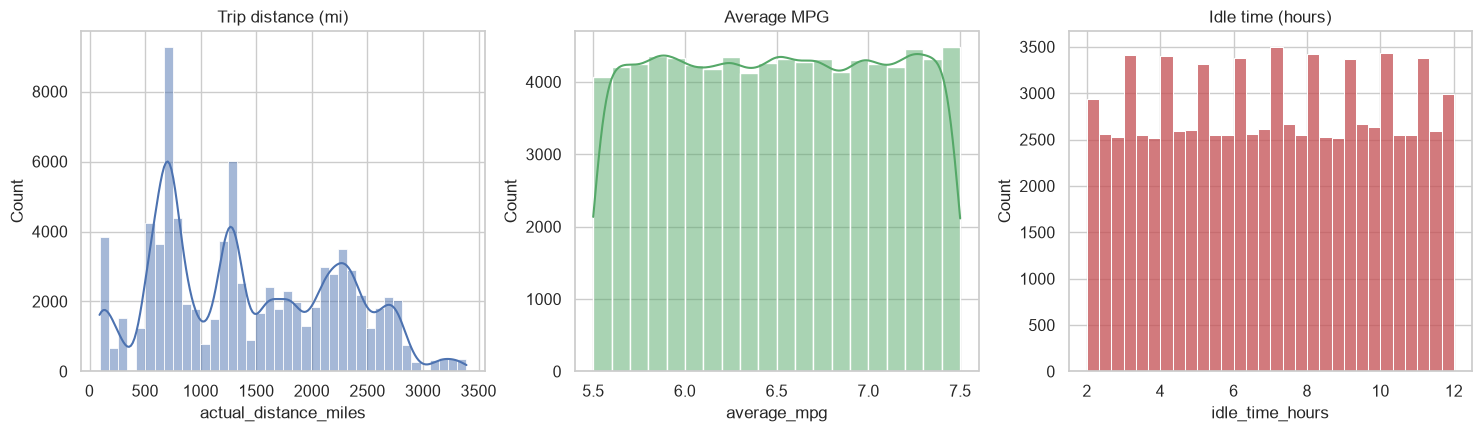

,actual_distance_miles,actual_duration_hours,fuel_gallons_used,average_mpg,idle_time_hours
count,"85,410.00","85,410.00","85,410.00","85,410.00","85,410.00"
mean,"1,430.27",25.01,221.83,6.50,7.01
std,801.93,14.19,126.56,0.58,2.88
min,90.00,1.40,12.00,5.50,2.00
25%,717.00,12.60,111.80,6.00,4.50
50%,"1,297.50",23.00,204.50,6.50,7.00
75%,"2,147.00",36.90,326.40,7.00,9.50
max,"3,391.00",67.80,611.90,7.50,12.00


MPG stddev: 0.578 (tight — synthetic data)
Idle share of duration: mean 0.541


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

sns.histplot(data=trips, x="actual_distance_miles", bins=40, kde=True, ax=axes[0], color="#4c72b0")
axes[0].set_title("Trip distance (mi)")

sns.histplot(data=trips, x="average_mpg", bins=20, kde=True, ax=axes[1], color="#55a868")
axes[1].set_title("Average MPG")

sns.histplot(data=trips, x="idle_time_hours", bins=30, ax=axes[2], color="#c44e52")
axes[2].set_title("Idle time (hours)")

plt.tight_layout()
plt.show()

trips["idle_share"] = trips["idle_time_hours"] / (trips["actual_duration_hours"] + 1e-9)
display(
    trips[["actual_distance_miles", "actual_duration_hours", "fuel_gallons_used", "average_mpg", "idle_time_hours"]]
    .describe()
    .round(2)
)
print("MPG stddev:", round(trips["average_mpg"].std(), 3), "(tight — synthetic data)")
print("Idle share of duration: mean", round(trips["idle_share"].mean(), 3))


## 10. Fuel purchases

Price volatility, station geography, and card usage — cost side of route profitability.


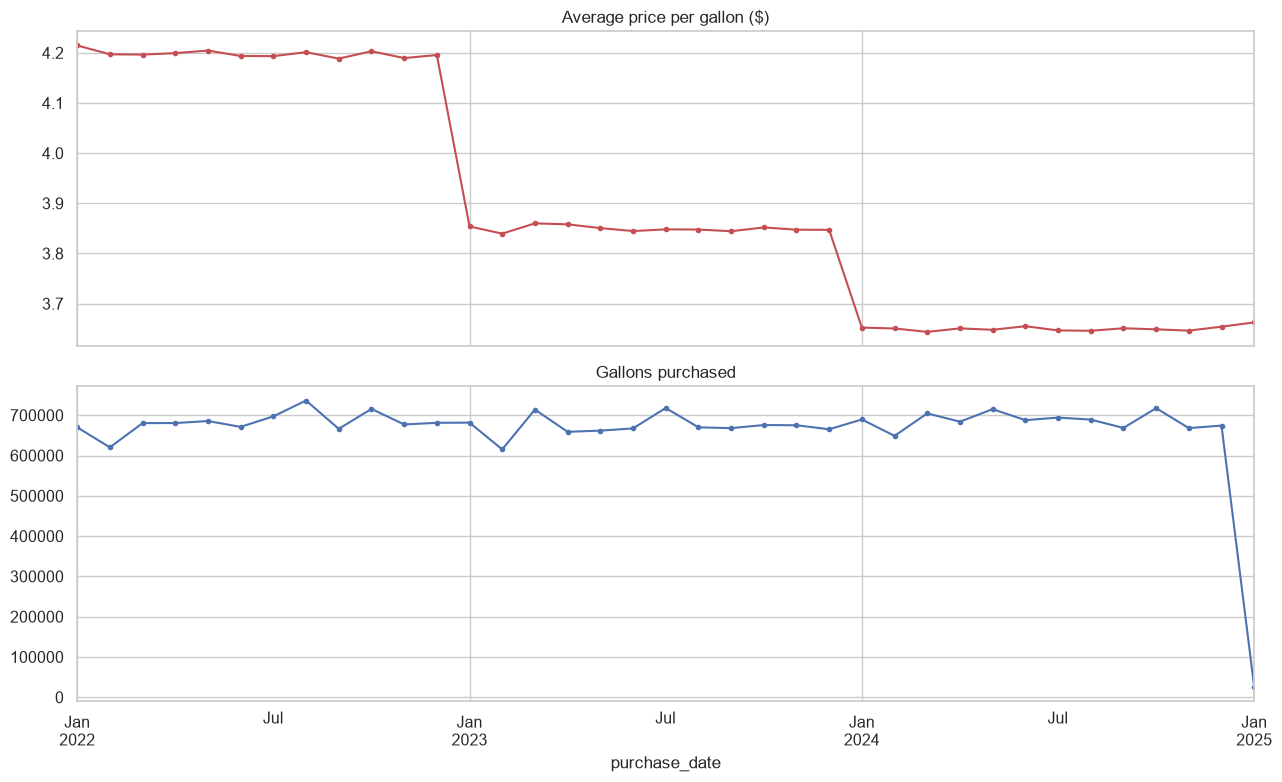

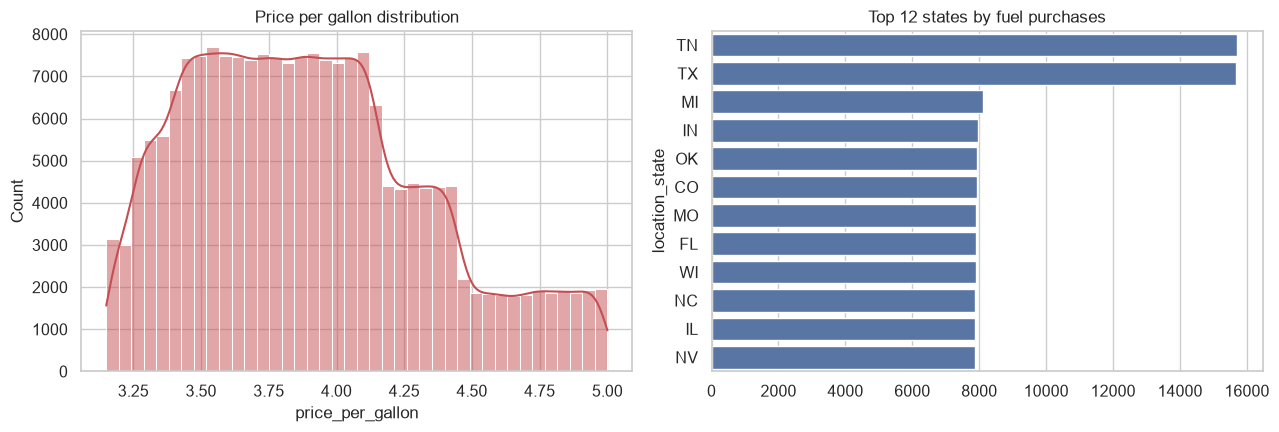

Total gallons: 24,519,038
Total fuel cost: $95,592,992
Avg PPG: 3.898


In [11]:
fuel_monthly = (
    fuel.set_index("purchase_date")
    .resample("ME")
    .agg(gallons=("gallons", "sum"), cost=("total_cost", "sum"), ppg=("price_per_gallon", "mean"))
)

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
fuel_monthly["ppg"].plot(ax=axes[0], color="#c44e52", marker="o", markersize=3)
axes[0].set_title("Average price per gallon ($)")
fuel_monthly["gallons"].plot(ax=axes[1], color="#4c72b0", marker="o", markersize=3)
axes[1].set_title("Gallons purchased")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=fuel, x="price_per_gallon", bins=40, kde=True, ax=axes[0], color="#c44e52")
axes[0].set_title("Price per gallon distribution")
top_states = fuel["location_state"].value_counts().head(12)
sns.barplot(x=top_states.values, y=top_states.index, ax=axes[1], color="#4c72b0")
axes[1].set_title("Top 12 states by fuel purchases")
plt.tight_layout()
plt.show()

print("Total gallons:", f"{fuel['gallons'].sum():,.0f}")
print("Total fuel cost:", f"${fuel['total_cost'].sum():,.0f}")
print("Avg PPG:", round(fuel["price_per_gallon"].mean(), 3))


## 11. Cross-table insights

Joins that feed the marts: revenue by customer, MPG by make, distance by lane, driver workload.


trip↔load join rows: 85410 | 1:1 OK: True


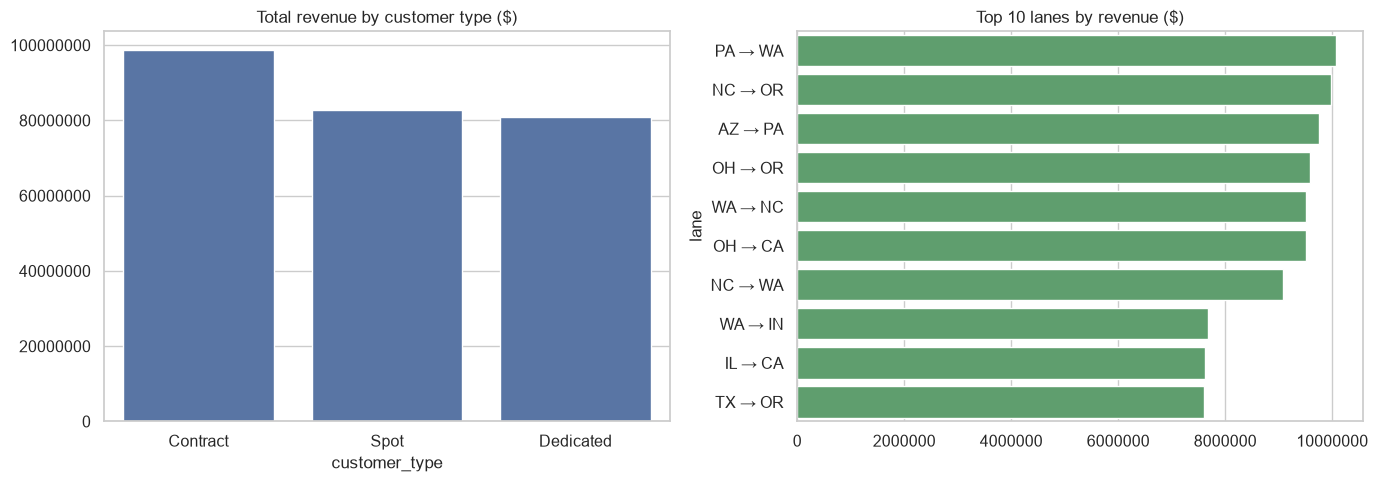

In [12]:
trip_load = trips.merge(loads, on="load_id", how="inner", validate="one_to_one")
trip_load = trip_load.merge(customers[["customer_id", "customer_type", "primary_freight_type"]], on="customer_id", how="left")
trip_load = trip_load.merge(routes[["route_id", "origin_state", "destination_state", "typical_distance_miles"]], on="route_id", how="left")
trip_load["lane"] = trip_load["origin_state"] + " → " + trip_load["destination_state"]
trip_load["revenue_per_mile"] = trip_load["revenue"] / trip_load["actual_distance_miles"].replace(0, np.nan)

print("trip↔load join rows:", len(trip_load), "| 1:1 OK:", len(trip_load) == len(trips))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
cust_rev = (
    trip_load.groupby("customer_type")["revenue"].sum().sort_values(ascending=False)
)
sns.barplot(x=cust_rev.index, y=cust_rev.values, ax=axes[0], color="#4c72b0")
axes[0].set_title("Total revenue by customer type ($)")
axes[0].ticklabel_format(axis="y", style="plain")

lane_rev = trip_load.groupby("lane")["revenue"].sum().nlargest(10)
sns.barplot(y=lane_rev.index, x=lane_rev.values, ax=axes[1], color="#55a868")
axes[1].set_title("Top 10 lanes by revenue ($)")
axes[1].ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()


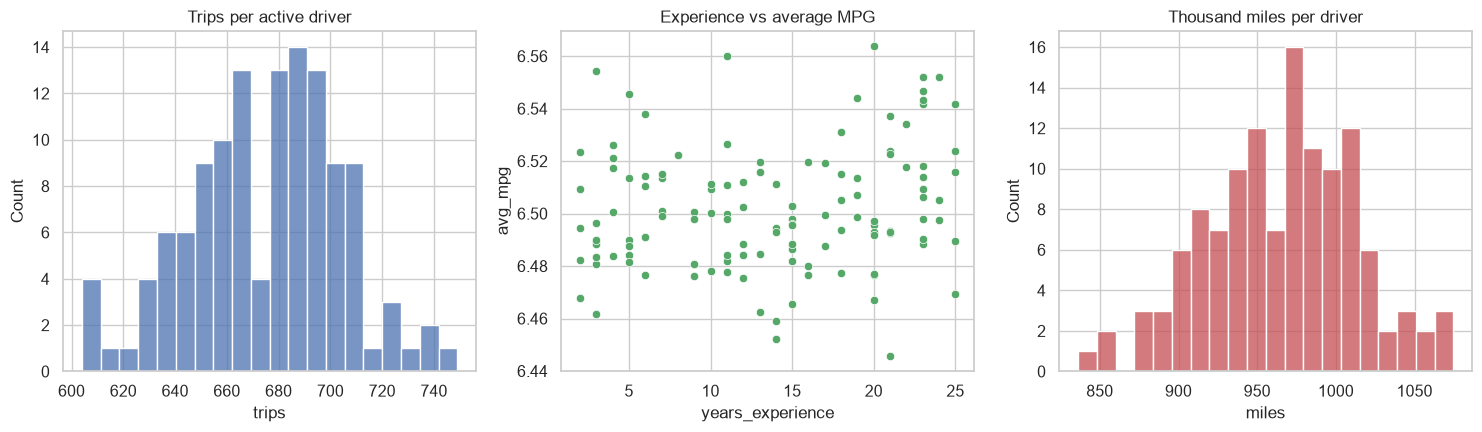

,trips,miles,avg_mpg,idle,years_experience
count,124.00,124.00,124.00,124.00,124.00
mean,674.97,"965,260.52",6.50,"4,730.91",13.71
std,29.36,"47,700.83",0.02,227.81,7.10
min,604.00,"836,187.00",6.45,"4,088.90",2.00
25%,656.25,"933,442.75",6.49,"4,609.27",7.00
50%,678.00,"970,395.00",6.50,"4,733.65",14.00
75%,696.25,"999,367.00",6.52,"4,896.00",20.00
max,749.00,"1,074,677.00",6.56,"5,262.30",25.00


In [13]:
# Driver workload (active drivers only)
active_ids = drivers.loc[drivers["employment_status"] == "Active", "driver_id"]
driver_stats = (
    trips[trips["driver_id"].isin(active_ids)]
    .groupby("driver_id")
    .agg(trips=("trip_id", "count"), miles=("actual_distance_miles", "sum"),
         avg_mpg=("average_mpg", "mean"), idle=("idle_time_hours", "sum"))
    .join(drivers.set_index("driver_id")[["years_experience", "home_terminal"]])
)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
sns.histplot(driver_stats["trips"], bins=20, ax=axes[0], color="#4c72b0")
axes[0].set_title("Trips per active driver")
sns.scatterplot(data=driver_stats, x="years_experience", y="avg_mpg", ax=axes[1], color="#55a868")
axes[1].set_title("Experience vs average MPG")
sns.histplot(driver_stats["miles"] / 1000, bins=20, ax=axes[2], color="#c44e52")
axes[2].set_title("Thousand miles per driver")
plt.tight_layout()
plt.show()

display(driver_stats.describe().round(2))


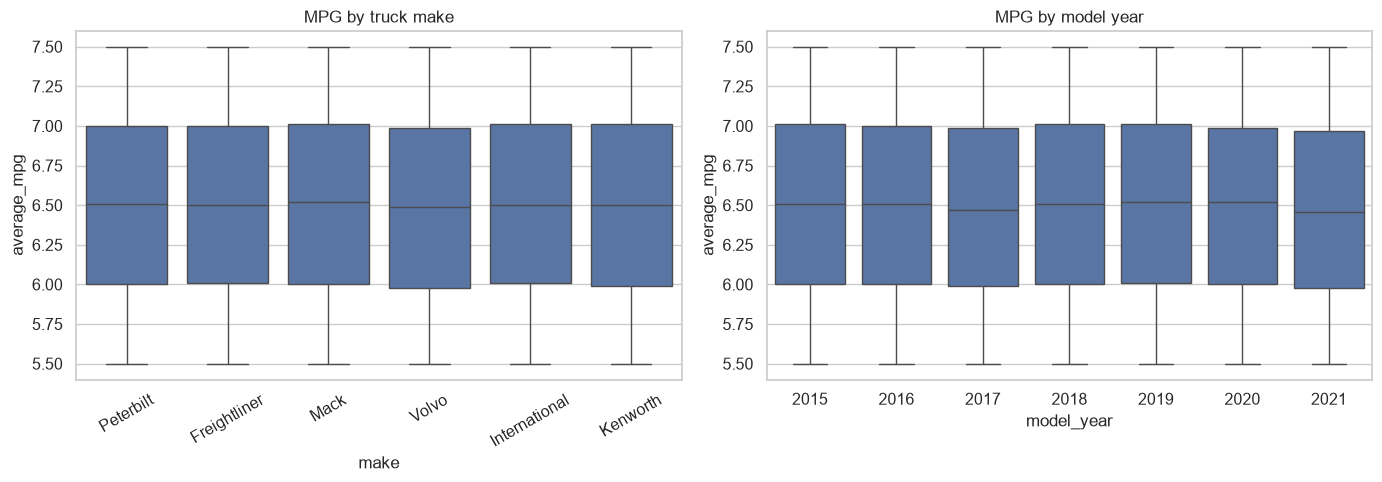

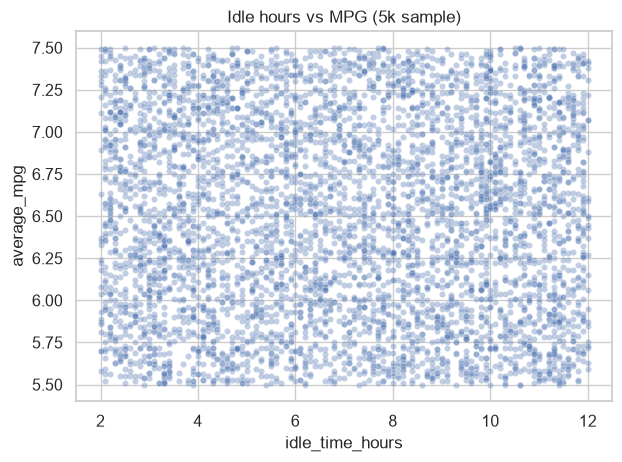

In [14]:
# MPG by truck make / model year — is there real separation?
truck_trips = trips.merge(trucks[["truck_id", "make", "model_year", "status"]], on="truck_id")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.boxplot(data=truck_trips, x="make", y="average_mpg", ax=axes[0], order=trucks["make"].value_counts().index)
axes[0].set_title("MPG by truck make")
axes[0].tick_params(axis="x", rotation=30)
sns.boxplot(data=truck_trips, x="model_year", y="average_mpg", ax=axes[1])
axes[1].set_title("MPG by model year")
plt.tight_layout()
plt.show()

# Maintenance-ish proxy: idle hours vs MPG
sns.scatterplot(data=trips.sample(5000, random_state=RANDOM), x="idle_time_hours", y="average_mpg", alpha=0.35, s=20)
plt.title("Idle hours vs MPG (5k sample)")
plt.tight_layout()
plt.show()


## 12. Correlation matrix

Numeric drivers of revenue and efficiency.


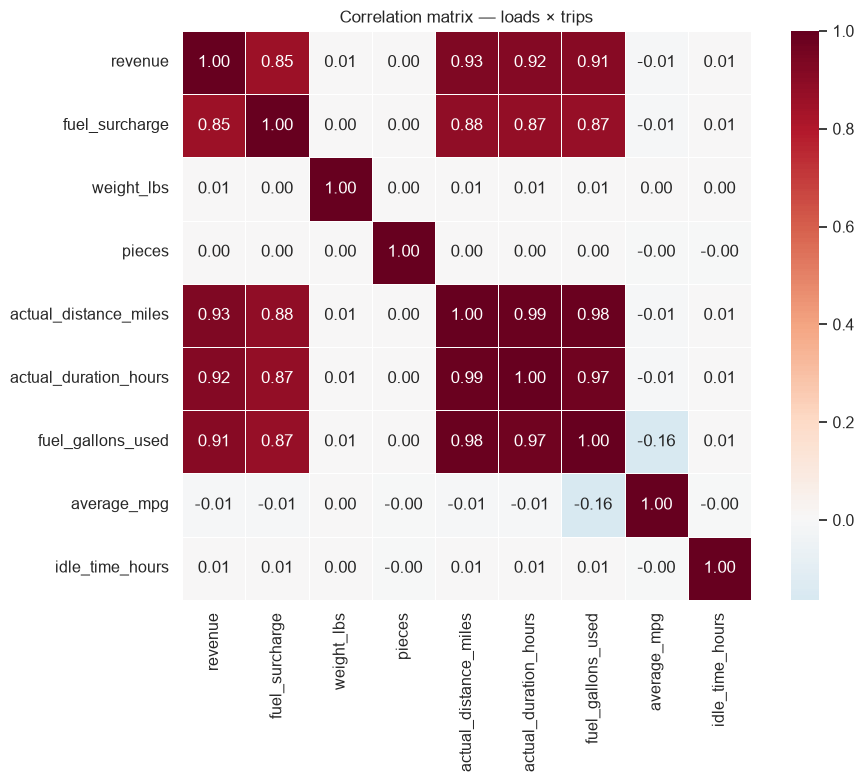

revenue                  1.00
actual_distance_miles    0.93
actual_duration_hours    0.92
fuel_gallons_used        0.91
fuel_surcharge           0.85
idle_time_hours          0.01
weight_lbs               0.01
pieces                   0.00
average_mpg             -0.01
Name: revenue, dtype: float64

In [15]:
num_cols = [
    "revenue", "fuel_surcharge", "weight_lbs", "pieces",
    "actual_distance_miles", "actual_duration_hours", "fuel_gallons_used",
    "average_mpg", "idle_time_hours",
]
corr = trip_load[num_cols].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=ax, square=True, linewidths=0.5)
ax.set_title("Correlation matrix — loads × trips")
plt.tight_layout()
plt.show()

display(corr["revenue"].sort_values(ascending=False).round(3))


## 13. MySQL EDA — summary

See `docs/FINDING.md` for the consolidated write-up across both notebooks.


In [16]:
print("Tables:", len(tables))
print("Total rows:", f"{sum(len(v) for v in tables.values()):,}")
print("Load window:", loads["load_date"].min().date(), "→", loads["load_date"].max().date())
print("Revenue:", f"${loads['revenue'].sum():,.0f}", "| Fuel cost:", f"${fuel['total_cost'].sum():,.0f}")
print("Avg MPG:", round(trips['average_mpg'].mean(), 2), "| On-time deliveries: see mongo notebook")


Tables: 9
Total rows: 368,020
Load window: 2022-01-01 → 2024-12-31
Revenue: $262,525,800 | Fuel cost: $95,592,992
Avg MPG: 6.5 | On-time deliveries: see mongo notebook
